# 02 · Préparation : fenêtres, découpage temporel, export

**Date :** 2 novembre 2026

**Ce qui est fait :**
1. Ajout de 4 caractéristiques de fenêtre par IP source et par minute : `w_conn`, `w_dst_ports`, `w_dst_hosts`, `w_rst_rate`.
2. Découpage train/val de lun, mar, mer, **temporel par classe** : pour chaque attaque, ses 80 % de flux les plus anciens en train, ses 20 % les plus récents en val ; le benign est coupé 80/20 dans chaque jour. Test = jeu + ven en entier.
3. Retrait des caractéristiques constantes sur train.
4. Contrôles, puis export dans `data/processed/{train,val,test}.parquet` + `features.json`.

**Pourquoi :**
- Les fenêtres rendent visible un comportement réparti sur plusieurs flux (scan, force brute) même quand on regarde un seul flux.
- Le notebook 01 a montré qu'un 80/20 par jour ne laisse presque aucune attaque en val (11 heartbleed). Le découpage par classe reste temporel (aucun mélange aléatoire, la val est toujours *après* le train pour chaque classe) et donne des attaques connues en val pour régler le RF et le MLP.

Aucun scaler ici : il sera ajusté sur train dans les notebooks 03 et 04 (règle 7).

In [1]:
import sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent / "src"))
from isocrates.ml.data import DAYS, ID_COLS, LABEL, BENIGN, TS, ROOT, feature_columns, read_header
from isocrates.ml.prepare import (WINDOW_COLS, TRAIN_FRAC, load_with_windows, temporal_split,
                                  constant_columns, model_features, save_split)

REPORTS, OUT = ROOT / "reports", ROOT / "data" / "processed"
sns.set_theme(style="whitegrid")
train_days = [d for d, (_, r) in DAYS.items() if r != "test"]
test_days = [d for d, (_, r) in DAYS.items() if r == "test"]
local = lambda t: pd.to_datetime(t, unit="us", utc=True).dt.tz_convert("America/Halifax")

## 1. Chargement de lun, mar, mer + caractéristiques de fenêtre

Fenêtres **fixes** de 60 s (minute Unix), calculées dans chaque jour séparément, à partir de `src_addr`, `dst_port`, `dst_addr` et `flag_rst` (qui vaut 0 ou 1). Les IP servent ici à regrouper, jamais comme caractéristiques (règle 4).

In [2]:
tv = load_with_windows(train_days)
print(f"{len(tv):,} flux · {tv.shape[1]} colonnes · {tv.memory_usage(deep=True).sum() / 1e9:.2f} Go")
tv.groupby(LABEL, observed=True)[WINDOW_COLS].median().sort_values("w_conn")

1,182,055 flux · 88 colonnes · 0.53 Go


,w_conn,w_dst_ports,w_dst_hosts,w_rst_rate
label,,,,
heartbleed,1.0,1.0,1.0,0.000000
ssh_patator,50.0,1.0,1.0,0.000000
ftp_patator,66.0,1.0,1.0,0.000000
benign,247.0,4.0,35.0,0.001195
dos_slowloris,265.0,1.0,1.0,0.328767
dos_slowhttptest,1008.0,1.0,1.0,0.039683
dos_goldeneye,1212.0,1.0,1.0,0.004125
dos_hulk,9688.0,1.0,1.0,0.000000


## 2. Découpage temporel par classe

In [3]:
tv["split"] = temporal_split(tv)
counts = pd.crosstab(tv[LABEL], tv["split"])
counts["part val"] = (counts["val"] / counts.sum(axis=1)).round(3)
counts.sort_values("train", ascending=False)

split,train,val,part val
label,,,
benign,799030,199759,0.200
dos_hulk,127190,31798,0.200
dos_goldeneye,5412,1353,0.200
dos_slowloris,4539,1135,0.200
dos_slowhttptest,3892,974,0.200
ftp_patator,3202,801,0.200
ssh_patator,2367,592,0.200
heartbleed,8,3,0.273


In [4]:
# Garantie temporelle : pour chaque groupe, le plus ancien flux de val est postérieur au plus récent de train
grp = np.where(tv[LABEL] == BENIGN, "benign_" + tv["day"], tv[LABEL].astype(str))
lim = tv.groupby([grp, "split"])[TS].agg(["min", "max"]).unstack("split")
check = pd.DataFrame({
    "fin train": local(lim[("max", "train")]).dt.strftime("%a %H:%M:%S"),
    "début val": local(lim[("min", "val")]).dt.strftime("%a %H:%M:%S"),
    "val après train": lim[("min", "val")] >= lim[("max", "train")],
})
assert check["val après train"].all()
check

,fin train,début val,val après train
benign_lun,Mon 15:15:31,Mon 15:15:31,True
benign_mar,Tue 15:24:32,Tue 15:24:32,True
benign_mer,Wed 15:16:55,Wed 15:16:55,True
dos_goldeneye,Wed 11:18:05,Wed 11:18:05,True
dos_hulk,Wed 10:57:19,Wed 10:57:19,True
dos_slowhttptest,Wed 10:33:28,Wed 10:33:28,True
dos_slowloris,Wed 10:05:42,Wed 10:05:43,True
ftp_patator,Tue 10:08:04,Tue 10:08:04,True
heartbleed,Wed 15:26:17,Wed 15:28:17,True
ssh_patator,Tue 14:58:03,Tue 14:58:03,True


## 3. Caractéristiques constantes (décidées sur train uniquement)

In [5]:
flow_feats = feature_columns(read_header())
dropped = constant_columns(tv[tv.split == "train"], flow_feats + WINDOW_COLS)
features = model_features(dropped)
print("Retirées (constantes sur train) :", dropped)
print(f"{len(features)} caractéristiques finales, dont fenêtres :", [f for f in features if f in WINDOW_COLS])

Retirées (constantes sur train) : ['flag_urg', 'fwd_flag_urg', 'bwd_flag_urg']
78 caractéristiques finales, dont fenêtres : ['w_conn', 'w_dst_ports', 'w_dst_hosts', 'w_rst_rate']


## 4. Test : jeu + ven (mêmes traitements, rien n'est ajusté dessus)

In [6]:
test = load_with_windows(test_days)
test["split"] = "test"
print(f"{len(test):,} flux de test")
test.groupby(LABEL, observed=True)[WINDOW_COLS].median().sort_values("w_conn")

655,443 flux de test


,w_conn,w_dst_ports,w_dst_hosts,w_rst_rate
label,,,,
webattack_sql_injection,4.0,1.0,1.0,0.000000
bot,19.0,4.0,5.0,0.000000
webattack_bruteforce,35.0,1.0,1.0,0.000000
webattack_xss,35.0,1.0,1.0,0.000000
benign,248.0,4.0,32.0,0.001754
ddos,4903.0,1.0,1.0,0.000000
portscan,43868.0,997.0,1.0,0.993937


## 5. Les fenêtres séparent-elles les classes ?

Échantillon d'au plus 5 000 flux par classe, **pour le graphique seulement** (graine fixe).

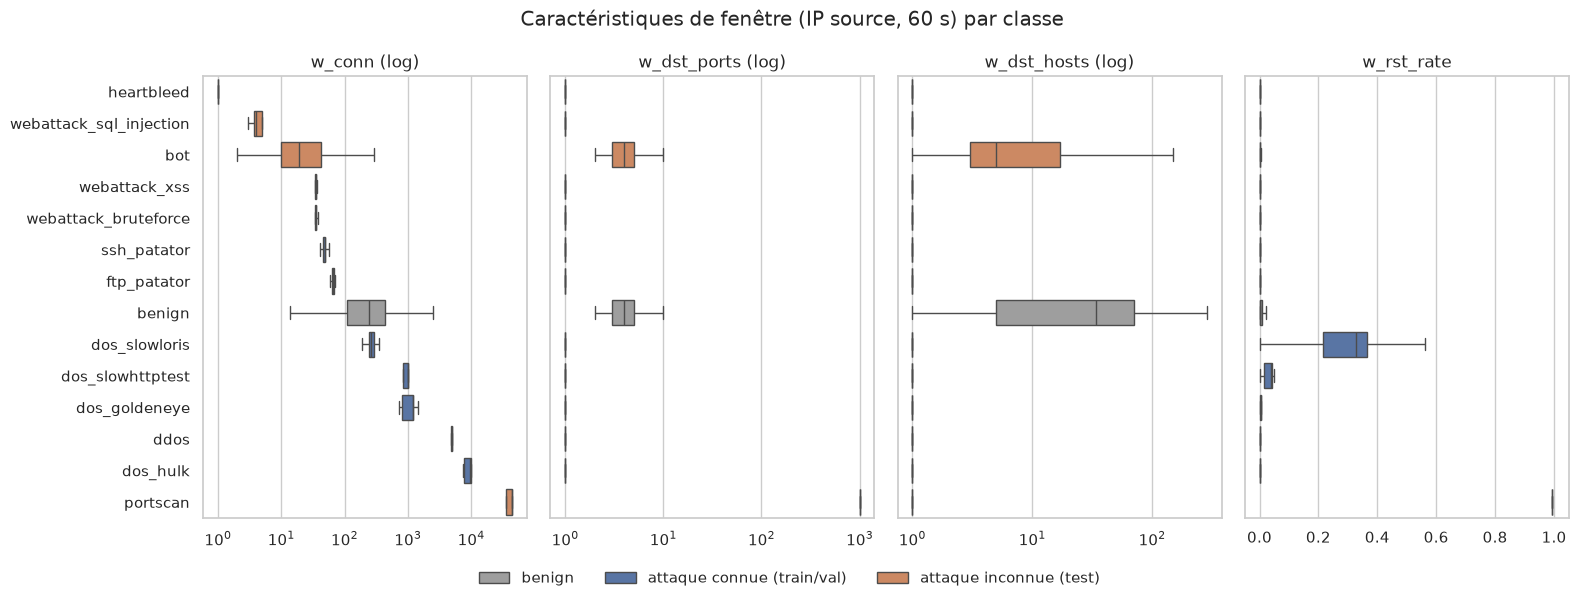

In [7]:
allf = pd.concat([tv[[LABEL] + WINDOW_COLS], test[[LABEL] + WINDOW_COLS]], ignore_index=True)
allf[LABEL] = allf[LABEL].astype(str)
idx = allf[LABEL].sample(frac=1, random_state=0).groupby(allf[LABEL]).head(5000).index
sample = allf.loc[idx]
order = sample.groupby(LABEL)["w_conn"].median().sort_values().index
test_attacks = set(test[LABEL].astype(str)) - {BENIGN}
kind = np.select([sample[LABEL] == BENIGN, sample[LABEL].isin(test_attacks)],
                 ["benign", "attaque inconnue (test)"], "attaque connue (train/val)")
colors = {"benign": "#9E9E9E", "attaque connue (train/val)": "#4C72B0", "attaque inconnue (test)": "#DD8452"}

fig, axes = plt.subplots(1, 4, figsize=(16, 6), sharey=True)
for ax, col in zip(axes, WINDOW_COLS):
    log = col != "w_rst_rate"
    sns.boxplot(data=sample, y=LABEL, x=col, order=order, ax=ax, fliersize=0, log_scale=log,
                hue=kind, palette=colors, dodge=False)
    ax.set_title(col + (" (log)" if log else ""))
    ax.set_xlabel(""); ax.set_ylabel("")
    ax.get_legend().remove()
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=3, frameon=False)
fig.suptitle("Caractéristiques de fenêtre (IP source, 60 s) par classe")
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(REPORTS / "02_fenetres_par_classe.png", dpi=150)
plt.show()

## 6. Contrôles et export

In [8]:
cols = ["day"] + ID_COLS + features
sets = {
    "train": tv.loc[tv.split == "train", cols].reset_index(drop=True),
    "val": tv.loc[tv.split == "val", cols].reset_index(drop=True),
    "test": test[cols].reset_index(drop=True),
}
total = sum(len(s) for s in sets.values())
assert total == 1_837_498, total
for name, s in sets.items():
    assert s[TS].dtype == "float64"
    assert not s[features].isna().any().any()
    assert np.isfinite(s[features].to_numpy()).all()

summary = pd.DataFrame({name: {
    "flux": len(s),
    "attaques": int((s[LABEL] != BENIGN).sum()),
    "classes d'attaque": s.loc[s[LABEL] != BENIGN, LABEL].nunique(),
    "jours": ", ".join(s["day"].unique()),
} for name, s in sets.items()}).T
summary

,flux,attaques,classes d'attaque,jours
train,945640,146610,7,"lun, mar, mer"
val,236415,36656,7,"lun, mar, mer"
test,655443,258557,6,"jeu, ven"


In [9]:
meta = {
    "split": "temporel par classe : 80 % les plus anciens de chaque attaque en train, 20 % en val ; "
             "benign 80/20 dans chaque jour ; test = jeu + ven",
    "train_frac": TRAIN_FRAC,
    "dropped_constant": dropped,
    "window_features": WINDOW_COLS,
    "window_seconds": 60,
    "timestamp_unit": "microsecondes Unix UTC (float64)",
    "id_columns": ID_COLS + ["day"],
    "rows": {k: len(v) for k, v in sets.items()},
}
save_split(sets, features, meta, OUT)

# Relecture : le timestamp doit être resté en float64
for name in sets:
    p = OUT / f"{name}.parquet"
    back = pd.read_parquet(p, columns=[TS])
    print(f"{p.name:15s} {p.stat().st_size / 1e6:6.0f} Mo · timestamp {back[TS].dtype}")

train.parquet      129 Mo · timestamp float64
val.parquet         33 Mo · timestamp float64
test.parquet        73 Mo · timestamp float64


## Observations

1. **Volumes.** Les 1 837 498 flux sont tous répartis : train 945 640 (dont 146 610 attaques), val 236 415 (dont 36 656 attaques), test 655 443 (dont 258 557 attaques). Le `timestamp` est bien resté en float64 dans les Parquet (129, 33 et 73 Mo).
2. **Découpage par classe.** Chaque attaque connue a 80 % de ses flux en train et 20 % en val (heartbleed : 8 / 3, trop peu pour une mesure stable). Pour chaque groupe, le premier flux de val est postérieur au dernier flux de train : aucune information du futur ne fuit dans le passé.
3. **Limite du découpage.** La val benign vient de la fin de chaque journée (après 15 h 15 environ), alors que la val d'une attaque vient de la fin de cette attaque (souvent le matin). Benign et attaques de val ne sont donc pas pris aux mêmes heures. À signaler dans le rapport.
4. **Caractéristiques.** Les 3 colonnes URG (constantes sur train) sont retirées : **78 caractéristiques** (74 de flux + 4 de fenêtre), listées dans `features.json`.
5. **Les fenêtres séparent nettement certaines attaques inconnues.** Portscan : médiane de 997 ports distincts par minute et 99 % de flux avec RST, contre 4 ports et 0,1 % pour le benign. DDoS (4 903 connexions/min) ressemble à dos_hulk (9 688) : le RF devrait au moins le classer comme « attaque ».
6. **D'autres risquent d'être confondues.** Les attaques web (35 connexions/min, 1 port, 1 machine) ont un profil proche de ssh/ftp_patator (50 et 66). Bot (19 connexions, 4 ports, 5 machines) ressemble au benign : c'est le cas le plus difficile.
7. **`w_conn` seul n'est pas un signe d'attaque.** La médiane benign est de 247 connexions/min, car beaucoup de sources normales sont des serveurs actifs.
8. **Fenêtres fixes** (minute Unix), pas glissantes : une rafale à cheval sur deux minutes est coupée en deux. Choix simple, à mentionner comme limite.